# 06 – Truy vấn dữ liệu trên MongoDB

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/<tài-khoản>/<repo>/blob/main/notebooks/06_truy_van_mongodb.ipynb)

| | |
|---|---|
| **Vai trò** | Thực hành CRUD trên collection thử nghiệm `demo_orders` và Aggregation Pipeline (doanh thu theo tháng, danh mục, bang, sản phẩm). |
| **Đầu vào** | Cơ sở dữ liệu `olist` đã nạp bởi `05_import_mongodb` và chuỗi kết nối Atlas (nhập qua `getpass`). |
| **Đầu ra** | Kết quả truy vấn và biểu đồ hiển thị trong notebook. |
| **Tương ứng báo cáo** | Mục 3.3. |
| **Cần chạy trước** | Cần chạy `05_import_mongodb` trước. |

*Đồ án Big Data – Nhóm 6 · Dữ liệu: Brazilian E-Commerce Public Dataset by Olist.*


## **Cài đặt kết nối và thư viện**
Chuỗi kết nối:
mongodb+srv://<tên_người_dùng>:<mật_khẩu>@<địa_chỉ_cluster>/?appName=Cluster0

**Lưu ý khi chạy:** xin nhóm tài khoản kết nối thật (nên dùng tài khoản chỉ đọc); cluster Atlas cần cho phép địa chỉ IP của bạn (Atlas → Network Access). Chuỗi kết nối được nhập qua `getpass` nên không bị lưu trong notebook.

In [ ]:
!pip -q install pymongo
import getpass
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
from pymongo import MongoClient, DESCENDING

client = MongoClient(getpass.getpass('Dán chuỗi kết nối: '), serverSelectionTimeoutMS=10000)
client.admin.command('ping')
db = client['olist']
print('Kết nối OK:', db.list_collection_names())

pd.set_option('display.width', 200, 'display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def run(pipeline, coll='orders', cols=None):
    df = pd.DataFrame(list(db[coll].aggregate(pipeline, allowDiskUse=True)))
    return df[cols] if cols else df

Dán chuỗi kết nối: ··········
Kết nối OK: ['sellers', 'products', 'geolocation', 'reviews', 'customers', 'orders']


**A. CRUD**

In [ ]:
#A0. Tạo collection demo_orders với 3 bản sao order thật
db.demo_orders.drop()
db.orders.aggregate([
    {'$match': {'status': 'delivered', 'customer_state': 'SP'}},
    {'$sort': {'_id': 1}},
    {'$limit': 3},
    {'$out': 'demo_orders'}
])
print('demo_orders:', db.demo_orders.count_documents({}), 'document (bản sao 3 đơn thật)')
for d in db.demo_orders.find({}, {'status': 1, 'customer_state': 1}):
    print(d)

demo_orders: 0 document (bản sao 3 đơn thật)


In [ ]:
#A1. CREATE – insert_one và insert_many (đúng cấu trúc document orders: nhúng items và payments)
r1 = db.demo_orders.insert_one({
    '_id': 'demo_0001', 'customer_id': 'c_demo', 'customer_unique_id': 'u_demo',
    'customer_state': 'SP', 'status': 'created', 'purchase_ts': datetime(2018, 8, 1, 10, 30),
    'items': [{'order_item_id': 1, 'product_id': 'p_demo', 'seller_id': 's_demo',
               'price': 100.0, 'freight_value': 15.0}],
    'payments': [{'payment_sequential': 1, 'payment_type': 'credit_card',
                  'payment_installments': 1, 'payment_value': 115.0}]
})
print('insert_one  →', r1.inserted_id)

r2 = db.demo_orders.insert_many([
    {'_id': 'demo_0002', 'customer_state': 'RJ', 'status': 'created',
     'purchase_ts': datetime(2018, 8, 2, 9, 0),
     'items': [{'order_item_id': 1, 'product_id': 'p_demo', 'seller_id': 's_demo', 'price': 250.0, 'freight_value': 30.0}],
     'payments': [{'payment_sequential': 1, 'payment_type': 'boleto', 'payment_installments': 1, 'payment_value': 280.0}]},
    {'_id': 'demo_0003', 'customer_state': 'SP', 'status': 'created',
     'purchase_ts': datetime(2018, 8, 3, 14, 15),
     'items': [{'order_item_id': 1, 'product_id': 'p_demo', 'seller_id': 's_demo', 'price': 60.0, 'freight_value': 10.0}],
     'payments': [{'payment_sequential': 1, 'payment_type': 'credit_card', 'payment_installments': 3, 'payment_value': 70.0}]},
])
print('insert_many →', r2.inserted_ids)
print('Tổng document trong demo_orders:', db.demo_orders.count_documents({}))

insert_one  → demo_0001
insert_many → ['demo_0002', 'demo_0003']
Tổng document trong demo_orders: 3


In [ ]:
#A2. READ – find, projection, sort, limit, toán tử trên mảng nhúng
print('1) find_one theo _id (có projection):')
print(db.demo_orders.find_one({'_id': 'demo_0001'}, {'status': 1, 'items.price': 1}))

print('\n2) Lọc + projection + sort + limit: 5 đơn SP gần nhất năm 2018 (collection thật, chỉ đọc)')
cur = (db.orders.find(
        {'status': 'delivered', 'customer_state': 'SP', 'purchase_ts': {'$gte': datetime(2018, 1, 1)}},
        {'customer_state': 1, 'purchase_ts': 1, 'items.price': 1})
       .sort('purchase_ts', DESCENDING).limit(5))
for d in cur: print(d)

print('\n3) Truy vấn trên mảng nhúng:')
print('Đơn có ít nhất 1 món giá > 1000                    :', db.orders.count_documents({'items.price': {'$gt': 1000}}))
print('Đơn có CÙNG MỘT món giá > 500 và phí ship > 100    :', db.orders.count_documents(
      {'items': {'$elemMatch': {'price': {'$gt': 500}, 'freight_value': {'$gt': 100}}}}))
print('Đơn có từ 3 món hàng trở lên                       :', db.orders.count_documents({'items.2': {'$exists': True}}))
print('Đơn thanh toán bằng nhiều hơn 1 khoản              :', db.orders.count_documents({'payments.1': {'$exists': True}}))

print('\n4) Toán tử $in:')
print('Đơn thất bại (canceled hoặc unavailable)            :', db.orders.count_documents(
      {'status': {'$in': ['canceled', 'unavailable']}}))

1) find_one theo _id (có projection):
{'_id': 'demo_0001', 'status': 'created', 'items': [{'price': 100.0}]}

2) Lọc + projection + sort + limit: 5 đơn SP gần nhất năm 2018 (collection thật, chỉ đọc)
{'_id': 'd70442bc5e3cb7438da497cc6a210f80', 'customer_state': 'SP', 'purchase_ts': datetime.datetime(2018, 8, 29, 10, 22, 35), 'items': [{'price': 6.9}]}
{'_id': 'bee12e8653a04e76786e8891cfb6330a', 'customer_state': 'SP', 'purchase_ts': datetime.datetime(2018, 8, 29, 8, 46, 11), 'items': [{'price': 91.55}, {'price': 91.55}, {'price': 91.55}, {'price': 91.55}, {'price': 91.55}]}
{'_id': 'dbb786f88b6d4e52fe3cb5d771b979d6', 'customer_state': 'SP', 'purchase_ts': datetime.datetime(2018, 8, 28, 21, 56, 30), 'items': [{'price': 149.9}]}
{'_id': '93d7e1f0c5415c1a0679635187700f1d', 'customer_state': 'SP', 'purchase_ts': datetime.datetime(2018, 8, 28, 16, 33, 22), 'items': [{'price': 179.0}]}
{'_id': 'd2ce2764e877473355ddb49af8eb3bc5', 'customer_state': 'SP', 'purchase_ts': datetime.datetime(2018, 

In [ ]:
#A3. UPDATE – $set, $push, update_many, $inc, $pull, upsert
r = db.demo_orders.update_one(
    {'_id': 'demo_0001'},
    {'$set': {'status': 'shipped'},
     '$push': {'items': {'order_item_id': 2, 'product_id': 'p_demo2', 'seller_id': 's_demo',
                         'price': 40.0, 'freight_value': 5.0}}})
print('update_one  → khớp', r.matched_count, '| sửa', r.modified_count)

r = db.demo_orders.update_many({'customer_state': 'SP'}, {'$set': {'note': 'đã kiểm tra'}})
print('update_many → khớp', r.matched_count, '| sửa', r.modified_count)

# $inc: tăng giá món đầu thêm 10
db.demo_orders.update_one({'_id': 'demo_0001'}, {'$inc': {'items.0.price': 10}})
# $pull: xóa món vừa $push khỏi mảng nhúng
db.demo_orders.update_one({'_id': 'demo_0001'}, {'$pull': {'items': {'order_item_id': 2}}})
# upsert: chưa có thì tạo mới
r = db.demo_orders.update_one({'_id': 'demo_0099'},
                              {'$set': {'status': 'created', 'customer_state': 'MG'}},
                              upsert=True)
print('upsert      → tạo mới:', r.upserted_id)

print(db.demo_orders.find_one({'_id': 'demo_0001'}, {'status': 1, 'items.price': 1, 'note': 1}))

update_one  → khớp 1 | sửa 1
update_many → khớp 2 | sửa 2
upsert      → tạo mới: demo_0099
{'_id': 'demo_0001', 'status': 'shipped', 'items': [{'price': 110.0}], 'note': 'đã kiểm tra'}


In [ ]:
#A4. DELETE – delete_one, delete_many
print('delete_one  →', db.demo_orders.delete_one({'_id': 'demo_0002'}).deleted_count, 'document')
print('delete_many →', db.demo_orders.delete_many({'note': {'$exists': True}}).deleted_count, 'document')
print('Còn lại trong demo_orders:', db.demo_orders.count_documents({}), '(demo_0099 do upsert tạo, không có note)')

db.demo_orders.drop()
print('Đã xóa demo_orders. orders thật vẫn còn:', db.orders.estimated_document_count(), 'document')

delete_one  → 1 document
delete_many → 2 document
Còn lại trong demo_orders: 1 (demo_0099 do upsert tạo, không có note)
Đã xóa demo_orders. orders thật vẫn còn: 50000 document


**B. Aggregation**

In [ ]:
#B1. Tổng doanh thu (tính một lần, dùng lại ở các cell sau)
DELIVERED = {'$match': {'status': 'delivered', 'items.0': {'$exists': True}}}
ORDER_REV = {'$sum': '$items.price'}
AOV = {'$round': [{'$divide': ['$revenue', '$n_orders']}, 2]}

total = run([
    DELIVERED,
    {'$group': {'_id': None, 'revenue': {'$sum': ORDER_REV}, 'n_orders': {'$sum': 1}}},
    {'$project': {'_id': 0, 'revenue': {'$round': ['$revenue', 2]}, 'n_orders': 1, 'aov': AOV}}
]).iloc[0]

TOTAL_REV = float(total['revenue'])
print('Tổng doanh thu :', TOTAL_REV)
print('Số đơn         :', int(total['n_orders']))
print('AOV            :', total['aov'])

Tổng doanh thu : 6680260.01
Số đơn         : 48519
AOV            : 137.68


  month  n_orders   revenue    aov
2016-09         1    134.97 134.97
2016-10       265  40325.11 152.17
2016-12         1     10.90  10.90
2017-01       750 111798.36 149.06
2017-02      1653 234223.40 141.70
2017-03      2546 359198.85 141.08
2017-04      2303 340669.68 147.92
2017-05      3546 489338.25 138.00
2017-06      3135 421923.37 134.58
2017-07      3872 481604.52 124.38
2017-08      4193 554699.70 132.29
2017-09      4150 607399.67 146.36
2017-10      4478 648247.65 144.76
2017-11      7289 987765.37 135.51
2017-12      5513 726033.19 131.69
2018-01      7069 924645.00 130.80
2018-02      6555 826437.13 126.08
2018-03      7003 953356.25 136.14
2018-04      6798 973534.09 143.21
2018-05      6749 977544.69 144.84
2018-06      6099 856077.86 140.36
2018-07      6159 867953.46 140.92
2018-08      6351 838576.64 132.04

Tổng theo tháng: 13221498.11 | Tổng toàn bộ: 6680260.01


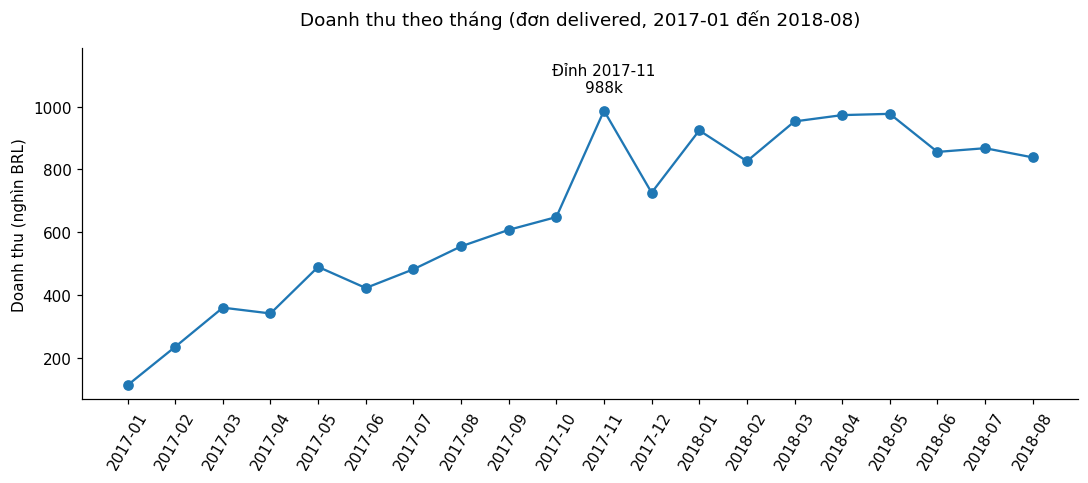

In [ ]:
#B2. Doanh thu theo tháng
monthly = run([
    DELIVERED,
    {'$group': {'_id': {'$dateToString': {'format': '%Y-%m', 'date': '$purchase_ts'}},
                'revenue': {'$sum': ORDER_REV}, 'n_orders': {'$sum': 1}}},
    {'$sort': {'_id': 1}},
    {'$project': {'_id': 0, 'month': '$_id', 'n_orders': 1,
                  'revenue': {'$round': ['$revenue', 2]}, 'aov': AOV}}
], cols=['month', 'n_orders', 'revenue', 'aov'])

print(monthly.to_string(index=False))
print('\nTổng theo tháng: %.2f | Tổng toàn bộ: %.2f' % (monthly['revenue'].sum(), TOTAL_REV))

trend = monthly[monthly['month'].between('2017-01', '2018-08')]  # giai đoạn ổn định

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(trend['month'], trend['revenue'] / 1e3, marker='o')
peak = trend.loc[trend['revenue'].idxmax()]
ax.annotate(f"Đỉnh {peak['month']}\n{peak['revenue']/1e3:,.0f}k",
            (peak['month'], peak['revenue'] / 1e3),
            xytext=(0, 12), textcoords='offset points', ha='center')
ax.set_ylabel('Doanh thu (nghìn BRL)')

# Tăng giới hạn trục Y thêm một khoảng nhỏ để nhãn không chạm mép trên cùng và tiêu đề
current_ylim = ax.get_ylim()
ax.set_ylim(current_ylim[0], current_ylim[1] * 1.15)

# Thêm tham số pad để đẩy tiêu đề lên cao hơn một chút
ax.set_title('Doanh thu theo tháng (đơn delivered, 2017-01 đến 2018-08)', pad=15)
plt.xticks(rotation=60); plt.tight_layout(); plt.show()

Số sản phẩm đã bán: 23611 | Tổng: 7998890.52
Tổng doanh thu: 6680260.01 | Số danh mục: 74
             category  items_sold  n_products   revenue  pct_revenue  cum_pct
        health_beauty        5671        1758 744074.87        11.14    11.14
        watches_gifts        3565         961 705517.97        10.56    21.70
       bed_bath_table        6531        2169 613346.47         9.18    30.88
       sports_leisure        5135        2093 579910.06         8.68    39.56
computers_accessories        4581        1204 539296.71         8.07    47.63
      furniture_decor        4876        1834 426770.27         6.39    54.02
           cool_stuff        2259         589 376823.37         5.64    59.66
                 auto        2583        1325 375725.47         5.62    65.28
           housewares        4060        1681 374008.28         5.60    70.88
                 toys        2378        1001 287445.65         4.30    75.18

Top 5 chiếm 47.6% | Top 10 chiếm 75.2%
Tổng theo da

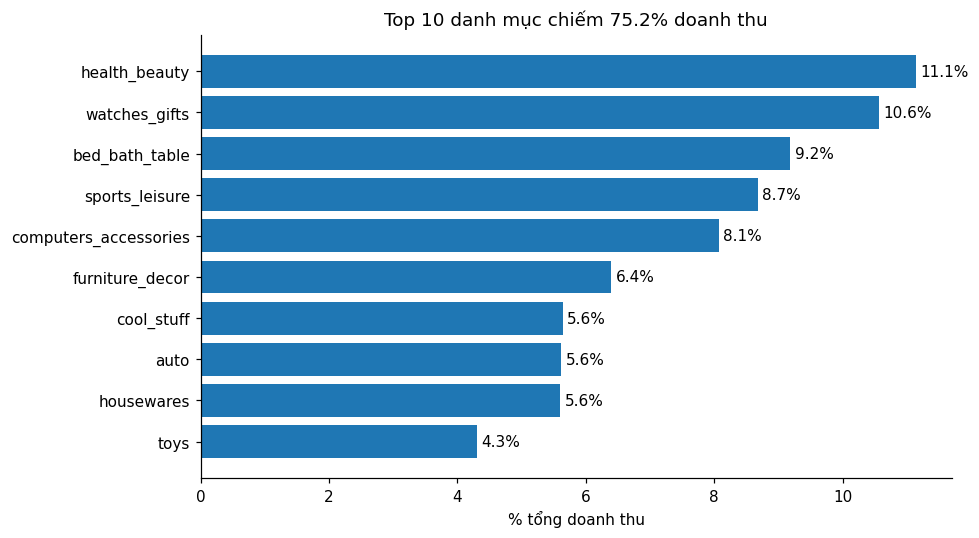

In [ ]:
#B3. Doanh thu theo danh mục sản phẩm
#B3a. Doanh số theo sản phẩm (một pipeline cho cả B3 và B5)
prod = pd.DataFrame(db.products.find({}, {'product_category_name': 1,
                                          'product_category_name_english': 1}))
prod['category'] = (prod['product_category_name_english']
                    .fillna(prod['product_category_name']).fillna('unknown'))
cat_map = prod.set_index('_id')['category']

sales = run([
    {'$match': {'status': 'delivered'}},
    {'$unwind': '$items'},
    {'$group': {'_id': {'o': '$_id', 'p': '$items.product_id'},
                'revenue': {'$sum': '$items.price'}, 'qty': {'$sum': 1}}},
    {'$group': {'_id': '$_id.p', 'revenue': {'$sum': '$revenue'},
                'qty': {'$sum': '$qty'}, 'n_orders': {'$sum': 1}}},
    {'$project': {'_id': 0, 'product_id': '$_id', 'revenue': 1, 'qty': 1, 'n_orders': 1}}
])
sales['category'] = sales['product_id'].map(cat_map).fillna('unknown')
print('Số sản phẩm đã bán:', len(sales), '| Tổng: %.2f' % sales['revenue'].sum())
#B3b. Doanh thu theo danh mục sản phẩm
category = (sales.groupby('category')
            .agg(items_sold=('qty', 'sum'), n_products=('product_id', 'nunique'),
                 revenue=('revenue', 'sum'))
            .sort_values('revenue', ascending=False).reset_index())
category['pct_revenue'] = (category['revenue'] / TOTAL_REV * 100).round(2)
category['cum_pct'] = category['pct_revenue'].cumsum().round(2)
category['revenue'] = category['revenue'].round(2)

print('Tổng doanh thu: %.2f | Số danh mục: %d' % (TOTAL_REV, len(category)))
print(category.head(10).to_string(index=False))
print('\nTop 5 chiếm %.1f%% | Top 10 chiếm %.1f%%' % (
      category.head(5)['pct_revenue'].sum(), category.head(10)['pct_revenue'].sum()))
print('Tổng theo danh mục: %.2f' % category['revenue'].sum())

top = category.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(top['category'], top['pct_revenue'])
ax.bar_label(bars, fmt='%.1f%%', padding=3)
ax.set_xlabel('% tổng doanh thu')
ax.set_title('Top 10 danh mục chiếm %.1f%% doanh thu' % top['pct_revenue'].sum())
plt.tight_layout(); plt.show()

Số bang: 27 | Tổng doanh thu: 7998890.52

Top 10 bang theo doanh thu:
state  n_orders    revenue    aov  pct_revenue  cum_pct
   SP     24494 3053180.53 124.65        45.70    45.70
   RJ      7491 1075185.39 143.53        16.09    61.79
   MG      6762  918181.21 135.79        13.74    75.53
   RS      3211  450740.47 140.37         6.75    82.28
   PR      2960  402179.34 135.87         6.02    88.30
   BA      1979  309170.94 156.23         4.63    92.93
   SC      2179  304939.77 139.94         4.56    97.49
   GO      1182  182854.87 154.70         2.74   100.23
   DF      1208  169024.03 139.92         2.53   102.76
   PE       997  156321.78 156.79         2.34   105.10

Top 5 bang chiếm 88.3% doanh thu

AOV cao nhất (bang ≥ 100 đơn):
state  n_orders    aov
   PB       315 231.99
   AL       230 197.35
   RN       280 180.58
   PA       576 179.98
   RO       148 178.98

AOV thấp nhất (bang ≥ 100 đơn):
state  n_orders    aov
   DF      1208 139.92
   PR      2960 135.87
   MG   

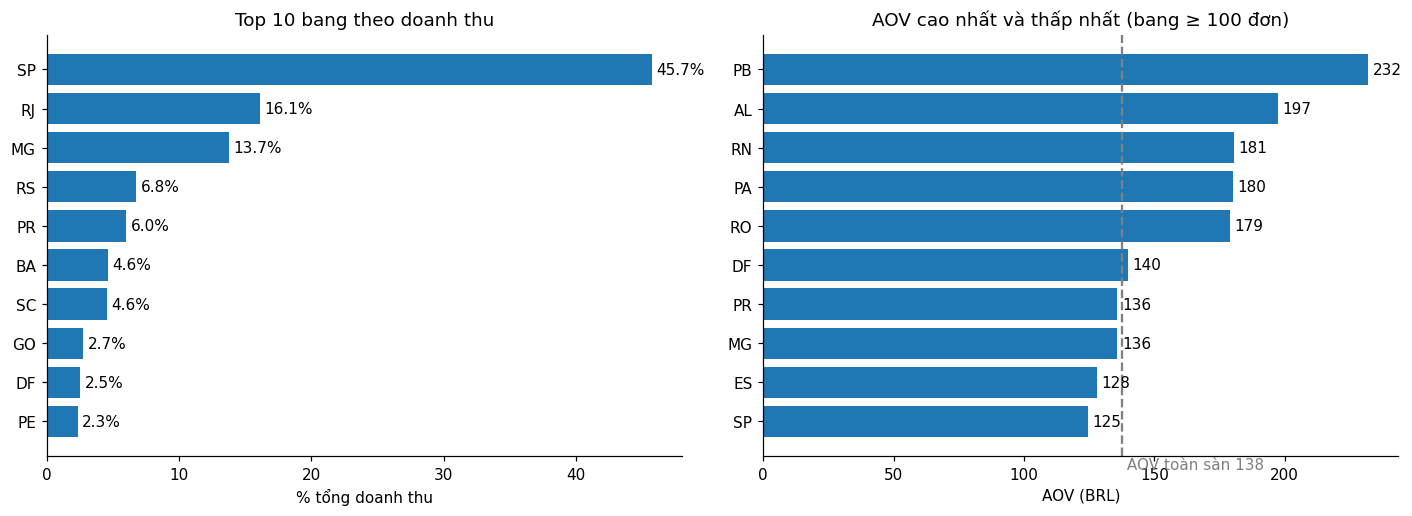

In [ ]:
#B4. Doanh thu và AOV theo bang
state = run([
    DELIVERED,
    {'$group': {'_id': '$customer_state', 'revenue': {'$sum': ORDER_REV}, 'n_orders': {'$sum': 1}}},
    {'$sort': {'revenue': -1}},
    {'$project': {'_id': 0, 'state': '$_id', 'n_orders': 1,
                  'revenue': {'$round': ['$revenue', 2]}, 'aov': AOV}}
], cols=['state', 'n_orders', 'revenue', 'aov'])

state['pct_revenue'] = (state['revenue'] / TOTAL_REV * 100).round(2)
state['cum_pct'] = state['pct_revenue'].cumsum().round(2)

print('Số bang:', len(state), '| Tổng doanh thu: %.2f' % state['revenue'].sum())
print('\nTop 10 bang theo doanh thu:')
print(state.head(10).to_string(index=False))
print('\nTop 5 bang chiếm %.1f%% doanh thu' % state.head(5)['pct_revenue'].sum())

#AOV: chỉ so sánh bang có từ 100 đơn trở lên
big = state[state['n_orders'] >= 100].sort_values('aov', ascending=False)
print('\nAOV cao nhất (bang ≥ 100 đơn):')
print(big.head(5)[['state', 'n_orders', 'aov']].to_string(index=False))
print('\nAOV thấp nhất (bang ≥ 100 đơn):')
print(big.tail(5)[['state', 'n_orders', 'aov']].to_string(index=False))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))

t = state.head(10).iloc[::-1]
a1.bar_label(a1.barh(t['state'], t['pct_revenue']), fmt='%.1f%%', padding=3)
a1.set_xlabel('% tổng doanh thu'); a1.set_title('Top 10 bang theo doanh thu')

a = pd.concat([big.head(5), big.tail(5)]).iloc[::-1]
a2.bar_label(a2.barh(a['state'], a['aov']), fmt='%.0f', padding=3)
avg_aov = float(total['aov'])
a2.axvline(avg_aov, ls='--', color='gray')
a2.text(avg_aov, -0.9, f' AOV toàn sàn {avg_aov:.0f}', color='gray', va='top')
a2.set_xlabel('AOV (BRL)'); a2.set_title('AOV cao nhất và thấp nhất (bang ≥ 100 đơn)')

plt.tight_layout(); plt.show()

In [ ]:
#B5. Top 10 sản phẩm theo doanh thu
top10 = sales.nlargest(10, 'revenue').copy()
top10['avg_price'] = (top10['revenue'] / top10['qty']).round(2)
top10['pct_revenue'] = (top10['revenue'] / TOTAL_REV * 100).round(2)
top10['revenue'] = top10['revenue'].round(2)
top10['product_id_short'] = top10['product_id'].str[:8] + '…'

print('Top 10 sản phẩm theo doanh thu:')
print(top10[['product_id_short', 'category', 'revenue', 'qty', 'n_orders',
             'avg_price', 'pct_revenue']].to_string(index=False))
print('\nTop 10 sản phẩm chiếm %.2f%% tổng doanh thu' % top10['pct_revenue'].sum())
print('Tổng doanh thu toàn sàn: %.2f' % TOTAL_REV)

Top 10 sản phẩm theo doanh thu:
product_id_short              category  revenue  qty  n_orders  avg_price  pct_revenue
       bb50f2e2…         health_beauty 39660.00  121       117     327.77         0.59
       d6160fb7…             computers 31499.70   23        23    1369.55         0.47
       6cdd5384…         health_beauty 29436.30   84        82     350.43         0.44
       5f504b3a…            cool_stuff 26827.30   45        45     596.16         0.40
       d1c42706… computers_accessories 25772.19  188       177     137.09         0.39
       99a4788c…        bed_bath_table 25459.97  289       274      88.10         0.38
       3dd2a171… computers_accessories 24143.90  161       147     149.96         0.36
       aca2eb7d…       furniture_decor 22366.30  313       257      71.46         0.33
       25c38557…                  baby 21646.55   21        21    1030.79         0.32
       53b36df6…         watches_gifts 20892.26  174       162     120.07         0.31

Top 10 sản